In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import certifi
import requests
from io import BytesIO

# Elektrisitestforbruk per bolig etter boligtype

In [27]:
url = 'https://data.ssb.no/api/pxwebapi/v2/tables/10573/data?lang=no&outputFormat=csv&valuecodes[Tid]=*&valuecodes[BygnType]=*&valuecodes[ContentsCode]=*&heading=Tid,ContentsCode&stub=BygnType'

response = requests.get(url, verify=certifi.where(), timeout=30)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content), header=0, sep=",", encoding="latin1")
df.head()

,BygnType,1995 Forbruk,1995 ForbrukSpes,2001 Forbruk,2001 ForbrukSpes,2004 Forbruk,2004 ForbrukSpes,2006 Forbruk,2006 ForbrukSpes,2009 Forbruk,2009 ForbrukSpes,2012 Forbruk,2012 ForbrukSpes,2022 Forbruk,2022 ForbrukSpes
0,1-8,23633,211,22399,203,21143,186,21644,190,20415,181,20230,185,17518,154
1,113,31911,238,31315,256,31136,216,32900,220,30599,219,30997,229,26633,172
2,111,28912,223,27327,214,26414,192,26680,199,25705,182,25776,198,22848,150
3,13,18818,205,18731,194,16850,179,17033,181,17726,186,17090,180,15673,149
4,14b,12817,178,11941,174,11367,173,12589,172,10541,166,10899,156,10552,159


In [3]:
bygninger = ['Alle bygningstyper', 'Våningshus', 'Enebolig', 'Rekkehus og kjedehus', 'Leilighet']

df['BygnType'] = bygninger

In [19]:
df_forbruk =df.filter(regex='Forbruk$')
df_forbruk.columns = df_forbruk.columns.str.replace(' Forbruk', '', regex=True)
df_forbruk.rename(columns=int, inplace=True)


/var/folders/4x/jb99p5tn7m30r1hlvpjwg2b00000gn/T/ipykernel_74034/1820639733.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_forbruk.rename(columns=int, inplace=True)


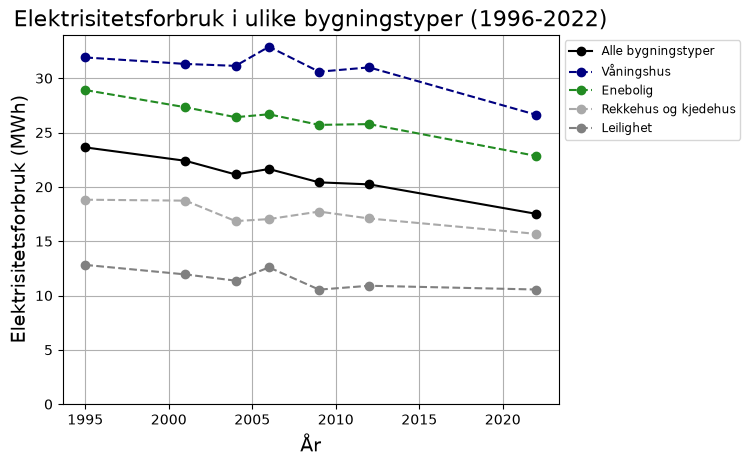

In [ ]:
plt.Figure(figsize=(10, 6))
plt.plot(df_forbruk.columns, df_forbruk.iloc[0] / 1e3, marker='o', label='Alle bygningstyper', color='black')
plt.plot(df_forbruk.columns, df_forbruk.iloc[1] / 1e3, marker='o', label='Våningshus', color='navy', linestyle='--')
plt.plot(df_forbruk.columns, df_forbruk.iloc[2] / 1e3, marker='o', label='Enebolig', color='forestgreen', linestyle='--')
plt.plot(df_forbruk.columns, df_forbruk.iloc[3] / 1e3, marker='o', label='Rekkehus og kjedehus', color='darkgrey', linestyle='--')
plt.plot(df_forbruk.columns, df_forbruk.iloc[4] / 1e3, marker='o', label='Leilighet', color='gray', linestyle='--')
plt.title('Elektrisitetsforbruk i ulike bygningstyper (1996-2022)', fontsize=16)
plt.xlabel('År', fontsize=14)
plt.ylabel('Elektrisitetsforbruk (MWh)', fontsize=14)
plt.ylim(bottom=0)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))
plt.grid()

In [29]:
df_per_areal = df.filter(regex='Spes$')
years = df_per_areal.columns.str.extract(r'(\d+)')[0]

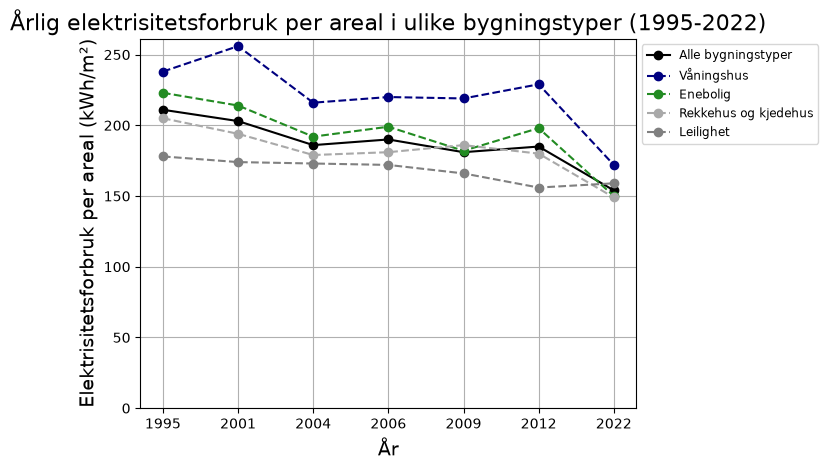

In [30]:
plt.Figure(figsize=(10, 6))
plt.plot(years, df_per_areal.iloc[0].astype(float), marker='o', label='Alle bygningstyper', color='black')
plt.plot(years, df_per_areal.iloc[1].astype(float), marker='o', label='Våningshus', color='navy', linestyle='--')
plt.plot(years, df_per_areal.iloc[2].astype(float), marker='o', label='Enebolig', color='forestgreen', linestyle='--')
plt.plot(years, df_per_areal.iloc[3].astype(float), marker='o', label='Rekkehus og kjedehus', color='darkgrey', linestyle='--')
plt.plot(years, df_per_areal.iloc[4].astype(float), marker='o', label='Leilighet', color='gray', linestyle='--')
plt.title('Årlig elektrisitetsforbruk per areal i ulike bygningstyper (1995-2022)', fontsize=16)
plt.xlabel('År', fontsize=14)
plt.ylabel('Elektrisitetsforbruk per areal (kWh/m²)', fontsize=14)
plt.ylim(bottom=0)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))
plt.grid()

# Energiforbruk per bolig etter energibærer

In [20]:
url = "https://data.ssb.no/api/pxwebapi/v2/tables/10572/data?lang=no&outputFormat=csv&valuecodes[Tid]=*&valuecodes[Energibaerer]=*&valuecodes[ContentsCode]=*&heading=Tid,ContentsCode&stub=Energibaerer"

response = requests.get(url, verify=certifi.where(), timeout=30)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content), header=0, sep=",", encoding="latin1")
df

,Energibaerer,1993 Forbruk,1993 ForbrukSpes,1994 Forbruk,1994 ForbrukSpes,1995 Forbruk,1995 ForbrukSpes,2001 Forbruk,2001 ForbrukSpes,2004 Forbruk,2004 ForbrukSpes,2006 Forbruk,2006 ForbrukSpes,2009 Forbruk,2009 ForbrukSpes,2012 Forbruk,2012 ForbrukSpes,2022 Forbruk,2022 ForbrukSpes
0,0,22706,207,23525,212,23633,211,22399,203,21143,186,21644,190,20415,181,20230,185,17518,154
1,0.01,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.
2,1.1,18064,167,18436,169,18537,169,17779,164,15991,145,16240,147,15977,146,16044,149,14964,131
3,3.0,1761,15,1718,15,1908,15,1217,11,1562,13,1411,12,845,7,698,6,0,0
4,2.02,2872,25,3274,27,3105,26,3331,28,3504,27,3853,30,3407,27,3204,27,2066,15
5,4-5,..,..,..,..,..,..,..,..,..,..,..,..,185,2,283,3,459,7


- Index 0: I alt
- Index 2: Elektrisitet
- Index 3: Olje og parafin
- Index 4: Ved, pellets og vedbriketter
- Index 5: Gass og fjernvarme 

## Forbruk per bolig per år

In [21]:
df_forbruk = df.filter(regex='Forbruk$')
aar = df_forbruk.columns.str.extract(r'(\d+)')[0]

i_alt = df_forbruk.iloc[0].astype(float)
elektrisitet = df_forbruk.iloc[2].astype(float)
olje_parafin = df_forbruk.iloc[3].astype(float)
ved = df_forbruk.iloc[4].astype(float)
gass_fjernvarme = df_forbruk.iloc[5].replace('..', 0).astype(float)

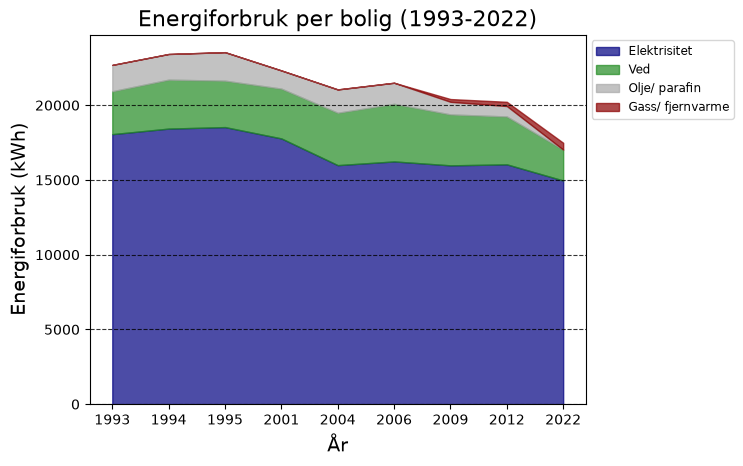

In [25]:
plt.Figure(figsize=(10, 6))
#plt.plot(aar, i_alt, label='I alt', color='black', linewidth=3)
plt.fill_between(aar, elektrisitet, 0, color = 'navy', label = 'Elektrisitet', alpha = 0.7)
plt.fill_between(aar,ved + elektrisitet, elektrisitet, color = 'forestgreen', label = 'Ved', alpha = 0.7)
plt.fill_between(aar, olje_parafin + ved + elektrisitet, ved + elektrisitet, color = 'darkgrey', label = 'Olje/ parafin', alpha = 0.7)
plt.fill_between(aar, gass_fjernvarme + olje_parafin + ved + elektrisitet, olje_parafin + ved + elektrisitet, color = 'darkred', label = 'Gass/ fjernvarme', alpha = 0.7)
plt.title('Energiforbruk per bolig (1993-2022)', fontsize=16)
plt.xlabel('År', fontsize=14)
plt.ylabel('Energiforbruk (kWh)', fontsize=14)
plt.ylim(bottom=0)
plt.legend(fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')